In [ ]:
!pip install pandas numpy requests scipy scikit-learn tqdm

In [ ]:
#!/usr/bin/env python3
"""
Thesis experiments for:
"Анализ современных методов прайсинга опционов с учётом микроструктуры финансовых рынков"

Pipeline:
1) Download Binance Options EOHSummary BTCUSDT data from data.binance.vision.
2) Parse option contracts, build mid prices, extract microstructure features.
3) Compute Black–Scholes implied volatilities from observed prices.
4) Build baseline model: BS with single constant volatility (no microstructure).
5) Build microstructure-aware IV model (RandomForest on microstructure features).
6) Compare pricing metrics (RMSE, IV RMSE, vega-weighted RMSE).
7) Run one-step delta-hedging backtest and compare hedging P&L stats.

Data source:
- Options EOHSummary: data/option/daily/EOHSummary/BTCUSDT/BTCUSDT-EOHSummary-YYYY-MM-DD.zip
  See Binance public data docs and EOHSummary listing.
"""

import os
import io
import math
import zipfile
import datetime as dt
from dataclasses import dataclass
from typing import List, Tuple, Dict, Optional

import numpy as np
import pandas as pd
import requests
from tqdm import tqdm

from scipy.stats import norm
from scipy.optimize import minimize_scalar, brentq
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor


# -----------------------
# CONFIG
# -----------------------

BINANCE_BASE_URL = "https://data.binance.vision"

# Date range for experiments (you can change this)
START_DATE = "2023-09-01"
END_DATE   = "2023-10-31"

OPTION_UNDERLYING_SYMBOL = "BTCUSDT"
RISK_FREE_RATE = 0.0  # Crypto context: we assume ~0 short-term rate
MIN_TIME_TO_MATURITY_DAYS = 1.0 / 24.0  # filter extremely near expiry (<1h)
MAX_TIME_TO_MATURITY_DAYS = 60.0        # optional cap on long-dated options

# Random seed for reproducibility
RANDOM_STATE = 42


# -----------------------
# UTILS
# -----------------------
def daterange(start_date: dt.date, end_date: dt.date):
    """Generator: yields all dates from start_date to end_date inclusive."""
    for n in range(int((end_date - start_date).days) + 1):
        yield start_date + dt.timedelta(n)


def ensure_dir(path: str):
    os.makedirs(path, exist_ok=True)


def download_zip(url: str, timeout: int = 30) -> Optional[bytes]:
    """
    Download zip file from Binance data. Return bytes or None if 404 / no data.
    """
    resp = requests.get(url, timeout=timeout)
    if resp.status_code == 200:
        return resp.content
    elif resp.status_code == 404:
        return None
    else:
        raise RuntimeError(f"Unexpected HTTP {resp.status_code} for {url}")


def load_single_csv_from_zip(zip_bytes: bytes) -> pd.DataFrame:
    """
    Many Binance data zips contain a single CSV. Extract and load as DataFrame.
    """
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        # choose the first .csv file
        csv_names = [n for n in zf.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise ValueError("Zip archive contains no CSV files")
        csv_name = csv_names[0]
        with zf.open(csv_name) as f:
            # EOHSummary data SHOULD have header row; if not, user will adjust.
            df = pd.read_csv(f)
    return df


def find_column(df: pd.DataFrame, candidates: List[str]) -> Optional[str]:
    """
    Try to find a column in df matching any of the candidate names (case-insensitive,
    also allowing substring matches). Returns actual column name or None.
    """
    cols_lower = {c.lower(): c for c in df.columns}
    # exact / near-exact
    for cand in candidates:
        cl = cand.lower()
        if cl in cols_lower:
            return cols_lower[cl]
    # substring fallback
    for c in df.columns:
        cl = c.lower()
        for cand in candidates:
            if cand.lower() in cl:
                return c
    return None


# -----------------------
# OPTION SYMBOL PARSING
# -----------------------

@dataclass
class ParsedOptionSymbol:
    underlying: str
    expiry: dt.date
    strike: float
    is_call: bool


def parse_binance_option_symbol(symbol: str) -> ParsedOptionSymbol:
    """
    Binance options symbol format (per official docs):
    Underlying-YYMMDD-Strike-OptionType, e.g. 'BTC-221230-20000-C'.
    See: Binance Options Contract Specifications.
    """
    parts = symbol.split("-")
    if len(parts) < 4:
        raise ValueError(f"Unexpected option symbol format: {symbol}")
    underlying = parts[0]
    datestr = parts[1]   # YYMMDD
    strike_str = parts[2]
    opt_type = parts[3].upper()

    year = int("20" + datestr[0:2])
    month = int(datestr[2:4])
    day = int(datestr[4:6])
    expiry = dt.date(year, month, day)

    strike = float(strike_str)
    is_call = opt_type == "C"

    return ParsedOptionSymbol(
        underlying=underlying,
        expiry=expiry,
        strike=strike,
        is_call=is_call
    )


# -----------------------
# BLACK–SCHOLES PRICING & GREEKS
# -----------------------

def bs_price(S: float, K: float, T: float, r: float, sigma: float, is_call: bool) -> float:
    """Black–Scholes price for European call/put."""
    if T <= 0:
        intrinsic = max(S - K, 0.0) if is_call else max(K - S, 0.0)
        return intrinsic
    if sigma <= 0:
        intrinsic = max(S - K, 0.0) if is_call else max(K - S, 0.0)
        return intrinsic
    sqrtT = math.sqrt(T)
    d1 = (math.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT
    if is_call:
        return S * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)
    else:
        return K * math.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


def bs_delta(S: float, K: float, T: float, r: float, sigma: float, is_call: bool) -> float:
    if T <= 0 or sigma <= 0:
        if is_call:
            return 1.0 if S > K else 0.0
        else:
            return -1.0 if S < K else 0.0
    sqrtT = math.sqrt(T)
    d1 = (math.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqrtT)
    if is_call:
        return norm.cdf(d1)
    else:
        return norm.cdf(d1) - 1.0


def bs_vega(S: float, K: float, T: float, r: float, sigma: float) -> float:
    """Vega wrt sigma (per 1.0 unit, not 1%): ∂Price/∂sigma."""
    if T <= 0 or sigma <= 0:
        return 0.0
    sqrtT = math.sqrt(T)
    d1 = (math.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * sqrtT)
    return S * norm.pdf(d1) * sqrtT


def implied_vol(price: float, S: float, K: float, T: float, r: float, is_call: bool,
                sigma_bounds: Tuple[float, float] = (1e-4, 3.0)) -> Optional[float]:
    """
    Compute BS implied volatility via root finding.
    Return None if not solvable (e.g. price < intrinsic or > no-arbitrage bounds).
    """
    intrinsic = max(S - K, 0.0) if is_call else max(K - S, 0.0)
    if price < intrinsic - 1e-8:
        return None
    # Quick upper bound: price can't exceed S for call, K*exp(-rT) for put
    if is_call and price > S * 1.01:
        return None
    if not is_call and price > K * math.exp(-r * T) * 1.01:
        return None

    def f(sigma):
        return bs_price(S, K, T, r, sigma, is_call) - price

    lo, hi = sigma_bounds
    try:
        # Ensure bracket sign change
        flo = f(lo)
        fhi = f(hi)
        if flo * fhi > 0:
            return None
        root = brentq(f, lo, hi, maxiter=100, xtol=1e-6)
        return float(root)
    except Exception:
        return None


# -----------------------
# LOAD OPTION EOHSummary
# -----------------------

def build_eohsummary_url(symbol: str, date: dt.date) -> str:
    """
    EOHSummary path:
    /data/option/daily/EOHSummary/BTCUSDT/BTCUSDT-EOHSummary-YYYY-MM-DD.zip
    """
    datestr = date.strftime("%Y-%m-%d")
    filename = f"{symbol}-EOHSummary-{datestr}.zip"
    url = f"{BINANCE_BASE_URL}/data/option/daily/EOHSummary/{symbol}/{filename}"
    return url


def load_eohsummary_date(symbol: str, date: dt.date) -> Optional[pd.DataFrame]:
    url = build_eohsummary_url(symbol, date)
    zip_bytes = download_zip(url)
    if zip_bytes is None:
        return None
    return load_single_csv_from_zip(zip_bytes)


def standardize_eohsummary(df_raw: pd.DataFrame) -> pd.DataFrame:
    """
    Привести EOHSummary Binance к единому виду.

    Работает с файлами формата (как в BTCUSDT-EOHSummary-2023-10-23.csv):
      - date, hour
      - symbol
      - best_bid_price, best_ask_price
      - mark_price (цена опциона, которую будем использовать как close_price)
      - volume_contracts, openinterest_contracts и т.д.
    """

    df = df_raw.copy()

    # 1) time: пробуем найти готовый столбец, если нет — собираем из date + hour
    time_col = find_column(df, ["time", "timestamp", "eohTime", "closeTime", "candleTime"])
    if time_col is None and "date" in df.columns and "hour" in df.columns:
        # EOHSummary даёт end-of-hour summary → строим datetime как date + hour:00
        df["time"] = (
            pd.to_datetime(df["date"].astype(str), errors="coerce") +
            pd.to_timedelta(df["hour"], unit="h")
        )
        time_col = "time"

    # 2) базовые колонки
    symbol_col = find_column(df, ["symbol", "contract", "optionSymbol"])
    bid_col    = find_column(df, ["best_bid_price", "bidPrice", "bestBidPrice", "bid_price"])
    ask_col    = find_column(df, ["best_ask_price", "askPrice", "bestAskPrice", "ask_price"])
    # ВАЖНО: добавляем mark_price как кандидат "close"
    close_col  = find_column(df, ["close", "closePrice", "markPrice", "mark_price", "lastPrice"])
    vol_col    = find_column(df, ["volume", "volume_contracts", "qty", "tradeVolume", "baseVolume"])
    oi_col     = find_column(df, ["openInterest", "open_interest", "openinterest_contracts", "oi"])

    # 3) проверки
    missing = []
    if time_col is None:
        missing.append("time/timestamp (или пара date+hour)")
    if symbol_col is None:
        missing.append("symbol/contract")
    if close_col is None and (bid_col is None or ask_col is None):
        missing.append("close/mark_price или пара best_bid_price/best_ask_price")

    if missing:
        raise RuntimeError(
            "Cannot standardize EOHSummary; missing key columns: "
            + ", ".join(missing)
            + "\n"
              "Посмотри df_raw.columns и поправь mapping в standardize_eohsummary()."
        )

    # 4) переименовываем в стандартные имена
    rename_map = {}
    if time_col:
        rename_map[time_col] = "time"
    if symbol_col:
        rename_map[symbol_col] = "symbol"
    if bid_col:
        rename_map[bid_col] = "bid_price"
    if ask_col:
        rename_map[ask_col] = "ask_price"
    if close_col:
        rename_map[close_col] = "close_price"
    if vol_col:
        rename_map[vol_col] = "volume"
    if oi_col:
        rename_map[oi_col] = "open_interest"

    df = df.rename(columns=rename_map)

    # 5) time → datetime
    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"])

    # 6) mid_price: сначала (bid+ask)/2, если пусто — fallback на close_price (mark_price)
    if "bid_price" in df.columns and "ask_price" in df.columns:
        df["mid_price"] = 0.5 * (df["bid_price"].astype(float) + df["ask_price"].astype(float))
        if "close_price" in df.columns:
            mask = df["mid_price"].isna()
            df.loc[mask, "mid_price"] = df.loc[mask, "close_price"].astype(float)
    else:
        df["mid_price"] = df["close_price"].astype(float)

    # 7) привести числовые колонки
    for col in ["bid_price", "ask_price", "close_price", "volume", "open_interest"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # 8) убрать странные строки с не положительной ценой
    df = df[df["mid_price"] > 0].copy()

    # 9) сортировка
    df = df.sort_values(["symbol", "time"]).reset_index(drop=True)

    return df


def load_eohsummary_range(symbol: str,
                          start_date: str,
                          end_date: str) -> pd.DataFrame:
    """
    Load EOHSummary for the given date range and standardize.
    """
    start = dt.datetime.strptime(start_date, "%Y-%m-%d").date()
    end = dt.datetime.strptime(end_date, "%Y-%m-%d").date()

    dfs = []
    print(f"Downloading EOHSummary for {symbol} from {start} to {end} ...")
    for d in tqdm(list(daterange(start, end))):
        try:
            df_raw = load_eohsummary_date(symbol, d)
        except Exception as e:
            print(f"[WARN] Error downloading {d}: {e}")
            df_raw = None
        if df_raw is None or df_raw.empty:
            continue
        try:
            df_std = standardize_eohsummary(df_raw)
            dfs.append(df_std)
        except Exception as e:
            print(f"[WARN] Error standardizing {d}: {e}")
            continue

    if not dfs:
        raise RuntimeError("No EOHSummary data loaded. Check date range and symbol.")
    df_all = pd.concat(dfs, ignore_index=True)
    return df_all


# -----------------------
# DATASET BUILDING
# -----------------------

# def build_pricing_dataset(df_eoh: pd.DataFrame) -> pd.DataFrame:
#     """
#     For each row in standardized EOHSummary, parse contract symbol, compute
#     time to maturity, moneyness, implied volatility etc.

#     Output columns (at least):
#     - time
#     - symbol
#     - mid_price
#     - S           (spot proxy: here we approximate with mark/mid of underlying index)
#       ==> IMPORTANT: EOHSummary is already index-based for BTCUSDT options; we
#           treat "underlying price" as an extra column if present (otherwise we
#           approximate with mid of nearest ATM option via put-call parity).
#       For robustness, we first try to detect an 'underlyingPrice' column.
#     - K
#     - T_years
#     - is_call
#     - log_moneyness
#     - iv            (implied vol from BS)
#     - vega_bs
#     plus all preserved microstructure columns as candidate features.
#     """
#     df = df_eoh.copy()

#     # Try to find underlying spot/index price column if present
#     underlying_col = find_column(df, ["underlyingPrice", "underlying_price", "indexPrice", "spotPrice"])
#     if underlying_col is None:
#         # Fallback: use mid_price as rough proxy for underlying (THIS IS CRUDE).
#         # In practice, you'd load BTCUSDT spot index or klines and merge.
#         print("[WARN] No explicit underlying price column found in EOHSummary. "
#               "Using mid_price as proxy (VERY CRUDE). "
#               "For thesis-quality results, merge real BTCUSDT spot index here.")
#         df["underlying_price"] = df["mid_price"]  # placeholder proxy
#     else:
#         df = df.rename(columns={underlying_col: "underlying_price"})

#     # Parse option symbols
#     parsed = df["symbol"].apply(parse_binance_option_symbol)
#     df["K"] = [p.strike for p in parsed]
#     df["is_call"] = [1 if p.is_call else 0 for p in parsed]
#     df["expiry_date"] = [p.expiry for p in parsed]

#     # Time to maturity in days/years
#     df["date"] = df["time"].dt.date
#     df["T_days"] = (df["expiry_date"] - df["date"]).apply(lambda x: x.days + 0.0)
#     # Filter unrealistic maturities
#     df = df[(df["T_days"] > MIN_TIME_TO_MATURITY_DAYS) &
#             (df["T_days"] <= MAX_TIME_TO_MATURITY_DAYS)].copy()

#     df["T_years"] = df["T_days"] / 365.0

#     # Spot proxy
#     df["S"] = df["underlying_price"].astype(float)
#     df["log_moneyness"] = np.log(df["S"] / df["K"])

#     # Compute implied vol
#     iv_list = []
#     for _, row in tqdm(df.iterrows(), total=len(df), desc="Computing implied vol"):
#         S = float(row["S"])
#         K = float(row["K"])
#         T = float(row["T_years"])
#         price = float(row["mid_price"])
#         is_call = bool(row["is_call"])
#         iv = implied_vol(price, S, K, T, RISK_FREE_RATE, is_call)
#         iv_list.append(iv)
#     df["iv"] = iv_list

#     # Drop rows with failed IV
#     df = df[~df["iv"].isna()].copy()

#     # Vega using BS with implied vol
#     vega_list = []
#     for _, row in df.iterrows():
#         vega_list.append(
#             bs_vega(float(row["S"]), float(row["K"]), float(row["T_years"]),
#                     RISK_FREE_RATE, float(row["iv"]))
#         )
#     df["vega_bs"] = vega_list

#     # Drop zero-vega rows (deep ITM/OTM near expiry)
#     df = df[df["vega_bs"] > 1e-6].copy()

#     return df

def build_pricing_dataset(df_eoh: pd.DataFrame) -> pd.DataFrame:
    df = df_eoh.copy()

    # 1) Спот. В твоих данных его нет → временный proxy.
    # Для реального диплома лучше отдельно подмешать BTCUSDT spot/index.
    underlying_col = find_column(df, ["underlyingPrice", "underlying_price", "indexPrice", "spotPrice"])
    if underlying_col is None:
        print("[WARN] No explicit underlying price column found in EOHSummary. "
              "Using mid_price as VERY ROUGH proxy for spot. "
              "Для нормальных результатов сюда надо слить реальный BTCUSDT spot/index.")
        df["underlying_price"] = df["mid_price"]
    else:
        df = df.rename(columns={underlying_col: "underlying_price"})

    # 2) Разбор опционного тикера
    parsed = df["symbol"].apply(parse_binance_option_symbol)
    df["K"]         = [p.strike  for p in parsed]
    df["is_call"]   = [1 if p.is_call else 0 for p in parsed]
    df["expiry_date"] = [p.expiry for p in parsed]

    # 3) Срок до экспирации
    df["date_only"] = df["time"].dt.date
    df["T_days"] = (df["expiry_date"] - df["date_only"]).apply(lambda x: x.days + 0.0)
    df = df[(df["T_days"] > MIN_TIME_TO_MATURITY_DAYS) &
            (df["T_days"] <= MAX_TIME_TO_MATURITY_DAYS)].copy()
    df["T_years"] = df["T_days"] / 365.0

    # 4) Признаки S и moneyness
    df["S"] = df["underlying_price"].astype(float)
    df["log_moneyness"] = np.log(df["S"] / df["K"])

    # 5) Имплайд вола: можно
    #    а) брать mark_iv Binance как "истинную" IV,
    #    б) или пересчитывать через root-finding.
    # Лучше использовать mark_iv как target для ML-модели:
    if "mark_iv" in df.columns:
        df["iv"] = pd.to_numeric(df["mark_iv"], errors="coerce")
    else:
        # fallback: считаем сами через BS implied vol
        iv_list = []
        for _, row in tqdm(df.iterrows(), total=len(df), desc="Computing implied vol"):
            S = float(row["S"])
            K = float(row["K"])
            T = float(row["T_years"])
            price = float(row["mid_price"])
            is_call = bool(row["is_call"])
            iv = implied_vol(price, S, K, T, RISK_FREE_RATE, is_call)
            iv_list.append(iv)
        df["iv"] = iv_list

    df = df[~df["iv"].isna()].copy()

    # 6) Vega для vega-weighted RMSE
    vega_list = []
    for _, row in df.iterrows():
        vega_list.append(
            bs_vega(float(row["S"]), float(row["K"]), float(row["T_years"]),
                    RISK_FREE_RATE, float(row["iv"]))
        )
    df["vega_bs"] = vega_list
    df = df[df["vega_bs"] > 1e-6].copy()

    return df


# -----------------------
# MICROSTRUCTURE BUCKETS (SPREAD & LIQUIDITY)
# -----------------------

def add_spread_liquidity_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Добавляем:
      - spread_abs, spread_rel
      - liquidity proxies: volume, open_interest (если есть)
    """
    out = df.copy()
    if "bid_price" in out.columns and "ask_price" in out.columns:
        out["spread_abs"] = out["ask_price"] - out["bid_price"]
        out["spread_rel"] = out["spread_abs"] / out["mid_price"]
    else:
        out["spread_abs"] = np.nan
        out["spread_rel"] = np.nan

    # volume / open_interest уже есть, просто убедимся в числовом типе
    for col in ["volume", "open_interest"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out

def experiment2_spread_liquidity(df_test_models: pd.DataFrame,
                                 n_bins: int = 4) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Эксперимент 2: чувствительность к bid-ask spread и ликвидности.

    df_test_models должен содержать:
      - mid_price, vega_bs
      - spread_rel, volume, open_interest
      - price_bs_const, iv_bs_const
      - price_local_vol, iv_local_vol
      - price_micro, iv_micro
    """

    df = df_test_models.copy()
    df = add_spread_liquidity_features(df)

    results_spread = []
    results_liq    = []

    # --- по spread_rel ---
    if df["spread_rel"].notna().sum() > 0:
        df_sp = df[df["spread_rel"].notna()].copy()
        df_sp["spread_bucket"] = pd.qcut(df_sp["spread_rel"], q=n_bins, labels=False, duplicates="drop")

        for b in sorted(df_sp["spread_bucket"].dropna().unique()):
            sub = df_sp[df_sp["spread_bucket"] == b]

            for model_name, price_col, iv_col in [
                ("BS const σ",          "price_bs_const",   "iv_bs_const"),
                ("Local vol (ML)",      "price_local_vol",  "iv_local_vol"),
                ("Microstructure RF",   "price_micro",      "iv_micro"),
            ]:
                m = compute_pricing_metrics(sub, model_price_col=price_col, model_iv_col=iv_col)
                results_spread.append({
                    "Bucket_type": "Spread",
                    "Bucket": int(b),
                    "Model": model_name,
                    "RMSE_IV": m.rmse_iv,
                    "Vega_weighted_RMSE": m.vega_weighted_rmse,
                    "Count": len(sub)
                })

    # --- по open_interest или volume, как proxy ликвидности ---
    liq_col = "open_interest" if "open_interest" in df.columns and df["open_interest"].notna().sum() > 0 else "volume"
    if liq_col in df.columns and df[liq_col].notna().sum() > 0:
        df_lq = df[df[liq_col].notna()].copy()
        df_lq["liq_bucket"] = pd.qcut(df_lq[liq_col], q=n_bins, labels=False, duplicates="drop")

        for b in sorted(df_lq["liq_bucket"].dropna().unique()):
            sub = df_lq[df_lq["liq_bucket"] == b]

            for model_name, price_col, iv_col in [
                ("BS const σ",          "price_bs_const",   "iv_bs_const"),
                ("Local vol (ML)",      "price_local_vol",  "iv_local_vol"),
                ("Microstructure RF",   "price_micro",      "iv_micro"),
            ]:
                m = compute_pricing_metrics(sub, model_price_col=price_col, model_iv_col=iv_col)
                results_liq.append({
                    "Bucket_type": "Liquidity",
                    "Bucket": int(b),
                    "Model": model_name,
                    "RMSE_IV": m.rmse_iv,
                    "Vega_weighted_RMSE": m.vega_weighted_rmse,
                    "Count": len(sub),
                    "Liq_proxy": liq_col
                })

    df_spread = pd.DataFrame(results_spread)
    df_liq    = pd.DataFrame(results_liq)

    print("\n=== Experiment 2: Spread buckets ===")
    print(df_spread)
    print("\nLaTeX spread table:")
    if not df_spread.empty:
        print(df_spread.to_latex(index=False, float_format="%.5f"))

    print("\n=== Experiment 2: Liquidity buckets ===")
    print(df_liq)
    print("\nLaTeX liquidity table:")
    if not df_liq.empty:
        print(df_liq.to_latex(index=False, float_format="%.5f"))

    return df_spread, df_liq

def train_test_split_time(df: pd.DataFrame, test_fraction: float = 0.3) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Time-series aware split: sort by time, cut by fraction.
    """
    df_sorted = df.sort_values("time").reset_index(drop=True)
    n = len(df_sorted)
    split_idx = int((1.0 - test_fraction) * n)
    df_train = df_sorted.iloc[:split_idx].copy()
    df_test = df_sorted.iloc[split_idx:].copy()
    return df_train, df_test


# -----------------------
# BASELINE: CONSTANT-SIGMA BLACK–SCHOLES
# -----------------------

def calibrate_constant_sigma(df_train: pd.DataFrame) -> float:
    """
    Calibrate a single global volatility sigma that minimises MSE of option prices
    on the training set.
    """

    S = df_train["S"].values
    K = df_train["K"].values
    T = df_train["T_years"].values
    is_call = df_train["is_call"].values.astype(bool)
    market_price = df_train["mid_price"].values

    def objective(sigma: float) -> float:
        if sigma <= 0:
            return 1e9
        model_prices = np.array([
            bs_price(S[i], K[i], T[i], RISK_FREE_RATE, sigma, bool(is_call[i]))
            for i in range(len(S))
        ])
        mse = mean_squared_error(market_price, model_prices)
        return mse

    res = minimize_scalar(objective, bounds=(0.05, 3.0), method="bounded",
                          options={"maxiter": 50})
    sigma_hat = float(res.x)
    print(f"[Baseline] Calibrated constant sigma = {sigma_hat:.4f}")
    return sigma_hat


def apply_constant_sigma(df: pd.DataFrame, sigma: float) -> pd.DataFrame:
    """
    Compute BS price, delta, vega using a single constant sigma for all rows.
    """
    n = len(df)
    prices = np.empty(n, dtype=float)
    deltas = np.empty(n, dtype=float)
    vegas  = np.empty(n, dtype=float)

    for j, (_, row) in enumerate(df.iterrows()):
        S = float(row["S"])
        K = float(row["K"])
        T = float(row["T_years"])
        is_call = bool(row["is_call"])

        prices[j] = bs_price(S, K, T, RISK_FREE_RATE, sigma, is_call)
        deltas[j] = bs_delta(S, K, T, RISK_FREE_RATE, sigma, is_call)
        vegas[j]  = bs_vega(S, K, T, RISK_FREE_RATE, sigma)

    out = df.copy()
    out["price_bs_const"] = prices
    out["delta_bs_const"] = deltas
    out["vega_bs_const"]  = vegas

    return out


# -----------------------
# MICROSTRUCTURE-AWARE MODEL
# -----------------------

def build_feature_sets(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, List[str], List[str]]:
    """
    Build feature matrices for:
    - baseline model (no microstructure)
    - microstructure-aware model

    Baseline features:
      [log_moneyness, T_years, is_call]

    Microstructure features:
      baseline features + any EOHSummary columns that look like microstructure:
      bid_price, ask_price, spread, volume, open_interest, etc.
    """
    base_features = ["log_moneyness", "T_years", "is_call"]

    micro_cols_candidates = []
    for col in df.columns:
        cl = col.lower()
        if col in ["time", "symbol", "date", "expiry_date",
                   "mid_price", "S", "K",
                   "iv", "vega_bs", "price_bs_const",
                   "delta_bs_const", "vega_bs_const"]:
            continue
        if any(key in cl for key in [
            "bid", "ask", "spread",
            "volume", "vol_", "open_interest", "oi",
            "gamma", "vega", "delta",
            "turnover", "liquidity"
        ]):
            micro_cols_candidates.append(col)

    micro_features = base_features + sorted(list(set(micro_cols_candidates)))

    X_base = df[base_features].copy()
    X_micro = df[micro_features].copy()

    # Handle NaNs
    X_base = X_base.fillna(0.0)
    X_micro = X_micro.fillna(0.0)

    return X_base, X_micro, base_features, micro_features


def train_microstructure_model(df_train: pd.DataFrame) -> Tuple[RandomForestRegressor, List[str]]:
    """
    Train RandomForestRegressor to predict implied volatility (iv)
    using microstructure-aware feature set.
    """
    _, X_micro, _, micro_features = build_feature_sets(df_train)
    y = df_train["iv"].values

    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    rf.fit(X_micro, y)
    print(f"[Microstructure] Trained RandomForest on {len(X_micro)} samples "
          f"and {X_micro.shape[1]} features.")
    return rf, micro_features

  # -----------------------
# LOCAL VOL (ML) IV SURFACE
# -----------------------

def train_local_vol_ml(df_train: pd.DataFrame) -> GradientBoostingRegressor:
    """
    Local vol (ML): модель implied vol как функции только (log_moneyness, T_years, is_call),
    без микроструктуры.
    """
    X = df_train[["log_moneyness", "T_years", "is_call"]].values
    y = df_train["iv"].values

    gb = GradientBoostingRegressor(
        n_estimators=400,
        max_depth=3,
        learning_rate=0.05,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    )
    gb.fit(X, y)
    print(f"[LocalVol-ML] Trained GB on {len(X)} samples.")
    return gb


def apply_local_vol_ml(df: pd.DataFrame,
                       model: GradientBoostingRegressor) -> pd.DataFrame:
    """
    Применяем LocalVol-ML модель: предсказываем iv, считаем BS price/delta/vega.
    """
    X = df[["log_moneyness", "T_years", "is_call"]].values
    iv_pred = model.predict(X)
    iv_pred = np.maximum(iv_pred, 1e-4)

    n = len(df)
    prices = np.empty(n, dtype=float)
    deltas = np.empty(n, dtype=float)
    vegas  = np.empty(n, dtype=float)

    for j, (_, row) in enumerate(df.iterrows()):
        S = float(row["S"])
        K = float(row["K"])
        T = float(row["T_years"])
        is_call = bool(row["is_call"])
        sigma = float(iv_pred[j])

        prices[j] = bs_price(S, K, T, RISK_FREE_RATE, sigma, is_call)
        deltas[j] = bs_delta(S, K, T, RISK_FREE_RATE, sigma, is_call)
        vegas[j]  = bs_vega(S, K, T, RISK_FREE_RATE, sigma)

    out = df.copy()
    out["iv_local_vol"]    = iv_pred
    out["price_local_vol"] = prices
    out["delta_local_vol"] = deltas
    out["vega_local_vol"]  = vegas

    return out

# -----------------------
# HESTON-LIKE PARAMETRIC IV SURFACE
# -----------------------

def train_heston_like_iv_surface(df_train: pd.DataFrame) -> np.ndarray:
    """
    Простая Heston-like параметризация:
        iv^2(k, T) = a0 + a1*T + a2*|k| + a3*k^2 + a4*T*k^2
    где k = log_moneyness.
    Калибруем коэффициенты a0..a4 методом наименьших квадратов.
    Возвращаем вектор параметров beta (shape: 5,).
    """
    k = df_train["log_moneyness"].values
    T = df_train["T_years"].values
    iv = df_train["iv"].values
    y = iv ** 2  # регрессируем variance

    X = np.column_stack([
        np.ones_like(k),  # a0
        T,                # a1
        np.abs(k),        # a2
        k ** 2,           # a3
        T * (k ** 2)      # a4
    ])

    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    print(f"[Heston-like] Fitted beta = {beta}")
    return beta


def apply_heston_like_model(df: pd.DataFrame, beta: np.ndarray) -> pd.DataFrame:
    """
    Применяем Heston-like IV surface к df:
    - считаем iv_heston_like для каждой строки,
    - считаем цену/дельту/вегу через BS.
    """
    k = df["log_moneyness"].values
    T = df["T_years"].values

    X = np.column_stack([
        np.ones_like(k),
        T,
        np.abs(k),
        k ** 2,
        T * (k ** 2)
    ])

    var_pred = X @ beta
    var_pred = np.maximum(var_pred, 1e-6)
    iv_pred = np.sqrt(var_pred)

    n = len(df)
    prices = np.empty(n, dtype=float)
    deltas = np.empty(n, dtype=float)
    vegas  = np.empty(n, dtype=float)

    for j, (_, row) in enumerate(df.iterrows()):
        S = float(row["S"])
        K = float(row["K"])
        TT = float(row["T_years"])
        is_call = bool(row["is_call"])
        sigma = float(iv_pred[j])

        prices[j] = bs_price(S, K, TT, RISK_FREE_RATE, sigma, is_call)
        deltas[j] = bs_delta(S, K, TT, RISK_FREE_RATE, sigma, is_call)
        vegas[j]  = bs_vega(S, K, TT, RISK_FREE_RATE, sigma)

    out = df.copy()
    out["iv_heston_like"]    = iv_pred
    out["price_heston_like"] = prices
    out["delta_heston_like"] = deltas
    out["vega_heston_like"]  = vegas

    return out


def apply_microstructure_model(df: pd.DataFrame,
                               model: RandomForestRegressor,
                               micro_features: List[str]) -> pd.DataFrame:
    """
    Apply microstructure IV model and compute BS prices/deltas using predicted IV.
    Uses positional indexing (0..N-1), not DataFrame index, so size mismatches cannot occur.
    """
    # Build feature matrix in the same order as df rows
    X_micro = df[micro_features].fillna(0.0)

    # Predict implied vols for each row
    iv_pred = model.predict(X_micro)   # shape: (len(df),)

    # Pre-allocate arrays for speed & safety
    n = len(df)
    prices = np.empty(n, dtype=float)
    deltas = np.empty(n, dtype=float)
    vegas  = np.empty(n, dtype=float)

    # Iterate positionally (0..n-1) to avoid index misalignment
    for j, (_, row) in enumerate(df.iterrows()):
        S = float(row["S"])
        K = float(row["K"])
        T = float(row["T_years"])
        is_call = bool(row["is_call"])

        sigma = float(iv_pred[j])
        if sigma <= 1e-4:
            sigma = 1e-4

        prices[j] = bs_price(S, K, T, RISK_FREE_RATE, sigma, is_call)
        deltas[j] = bs_delta(S, K, T, RISK_FREE_RATE, sigma, is_call)
        vegas[j]  = bs_vega(S, K, T, RISK_FREE_RATE, sigma)

    out = df.copy()
    out["iv_micro"]    = iv_pred
    out["price_micro"] = prices
    out["delta_micro"] = deltas
    out["vega_micro"]  = vegas

    return out


# -----------------------
# METRICS
# -----------------------

@dataclass
class PricingMetrics:
    rmse_price: float
    rmse_iv: Optional[float]
    vega_weighted_rmse: float


def compute_pricing_metrics(df: pd.DataFrame,
                            model_price_col: str,
                            model_iv_col: Optional[str] = None) -> PricingMetrics:
    """
    Compute:
    - RMSE of prices
    - RMSE of IV (if column provided)
    - Vega-weighted RMSE of price errors
    """
    market_price = df["mid_price"].values
    model_price = df[model_price_col].values
    price_err = model_price - market_price

    rmse_price = math.sqrt(mean_squared_error(market_price, model_price))

    if model_iv_col is not None:
        true_iv = df["iv"].values
        model_iv = df[model_iv_col].values
        rmse_iv = math.sqrt(mean_squared_error(true_iv, model_iv))
    else:
        rmse_iv = None

    vega = df["vega_bs"].values
    # vega-weighted RMSE: sqrt( sum( (err * sqrt(vega))^2 ) / sum(vega) )
    num = np.sum((price_err * np.sqrt(vega)) ** 2)
    den = np.sum(vega) + 1e-12
    vega_weighted_rmse = math.sqrt(num / den)

    return PricingMetrics(
        rmse_price=rmse_price,
        rmse_iv=rmse_iv,
        vega_weighted_rmse=vega_weighted_rmse
    )


def build_experiment1_table(df_train_bs: pd.DataFrame,
                            df_test_bs: pd.DataFrame,
                            df_train_heston: pd.DataFrame,
                            df_test_heston: pd.DataFrame,
                            df_train_local: pd.DataFrame,
                            df_test_local: pd.DataFrame,
                            df_train_micro: pd.DataFrame,
                            df_test_micro: pd.DataFrame) -> pd.DataFrame:
    """
    Строит таблицу:
        Модель × (In-sample / Out-of-sample) → RMSE IV, Vega-weighted RMSE.
    Возвращает DataFrame и печатает LaTeX-таблицу.
    """

    rows = []

    # Helper
    def add_row(name, split, df, price_col, iv_col):
        m = compute_pricing_metrics(df, model_price_col=price_col, model_iv_col=iv_col)
        rows.append({
            "Model": name,
            "Split": split,
            "RMSE_IV": m.rmse_iv,
            "Vega_weighted_RMSE": m.vega_weighted_rmse
        })

    # BS const sigma (iv_bs_const уже есть или добавим)
    add_row("Black--Scholes (const σ)", "In-sample",
            df_train_bs, "price_bs_const", "iv_bs_const")
    add_row("Black--Scholes (const σ)", "Out-of-sample",
            df_test_bs, "price_bs_const", "iv_bs_const")

    # Heston-like
    add_row("Heston-like surface", "In-sample",
            df_train_heston, "price_heston_like", "iv_heston_like")
    add_row("Heston-like surface", "Out-of-sample",
            df_test_heston, "price_heston_like", "iv_heston_like")

    # Local vol (ML)
    add_row("Local volatility (ML)", "In-sample",
            df_train_local, "price_local_vol", "iv_local_vol")
    add_row("Local volatility (ML)", "Out-of-sample",
            df_test_local, "price_local_vol", "iv_local_vol")

    # Microstructure-aware
    add_row("Microstructure-aware (RF)", "In-sample",
            df_train_micro, "price_micro", "iv_micro")
    add_row("Microstructure-aware (RF)", "Out-of-sample",
            df_test_micro, "price_micro", "iv_micro")

    df_tab = pd.DataFrame(rows)
    print("\n=== Experiment 1: RMSE(IV) & Vega-weighted RMSE ===")
    print(df_tab)

    # LaTeX-таблица в стиле твоего примера
    latex = df_tab.pivot(index="Model", columns="Split",
                         values=["RMSE_IV", "Vega_weighted_RMSE"])
    print("\nLaTeX table candidate for thesis:")
    print(latex.to_latex(float_format="%.5f"))

    return df_tab


def print_pricing_comparison(metrics_bs: PricingMetrics,
                             metrics_micro: PricingMetrics,
                             label_bs: str = "BS const sigma",
                             label_micro: str = "Microstructure RF") -> None:
    print("\n=== Pricing comparison (Test set) ===")
    print(f"{'Model':30s}  {'RMSE Price':>12s}  {'RMSE IV':>12s}  {'Vega-w RMSE':>12s}")
    print("-" * 70)
    iv_bs_str = f"{metrics_bs.rmse_iv:.5f}" if metrics_bs.rmse_iv is not None else "   n/a   "
    iv_m_str = f"{metrics_micro.rmse_iv:.5f}" if metrics_micro.rmse_iv is not None else "   n/a   "
    print(f"{label_bs:30s}  {metrics_bs.rmse_price:12.5f}  {iv_bs_str:>12s}  {metrics_bs.vega_weighted_rmse:12.5f}")
    print(f"{label_micro:30s}  {metrics_micro.rmse_price:12.5f}  {iv_m_str:>12s}  {metrics_micro.vega_weighted_rmse:12.5f}")
    print("=====================================\n")


# -----------------------
# DELTA-HEDGING BACKTEST (ONE-STEP)
# -----------------------

@dataclass
class HedgingStats:
    mean_pnl: float
    std_pnl: float
    rmse_pnl: float
    skew_pnl: float


def one_step_delta_hedge(df: pd.DataFrame,
                         price_col: str,
                         delta_col: str,
                         transaction_cost_bps: float = 1.0) -> HedgingStats:
    """
    One-step hedging P&L:
    At time t, long 1 option, short delta_t units of underlying.
    At t+Δt, close position. P&L_t = (C_{t+1} - C_t) - delta_t * (S_{t+1} - S_t) - costs.

    We do this for consecutive rows with the same (symbol) and hour steps.
    Transaction costs: proportional to notional traded in underlying.
      cost = cost_rate * |delta_t| * S_t + cost_rate * |delta_t| * S_{t+1}
    where cost_rate = transaction_cost_bps * 1e-4.
    """
    df = df.sort_values(["symbol", "time"]).reset_index(drop=True)

    pnl_list = []

    cost_rate = transaction_cost_bps * 1e-4

    for sym, grp in df.groupby("symbol"):
        grp = grp.sort_values("time").reset_index(drop=True)
        if len(grp) < 2:
            continue
        C = grp[price_col].values
        S = grp["S"].values
        delta = grp[delta_col].values
        # one-step P&L from t to t+1
        for t in range(len(grp) - 1):
            dC = C[t + 1] - C[t]
            dS = S[t + 1] - S[t]
            # hedge position is short delta_t underlying (to hedge long option)
            pnl = dC - delta[t] * dS
            # approximate transaction costs
            cost = cost_rate * (abs(delta[t]) * S[t] + abs(delta[t]) * S[t + 1])
            pnl -= cost
            pnl_list.append(pnl)

    if not pnl_list:
        raise RuntimeError("No hedging steps computed; dataset too small or time ordering broken.")

    pnl_arr = np.array(pnl_list)
    mean_pnl = float(np.mean(pnl_arr))
    std_pnl = float(np.std(pnl_arr))
    rmse_pnl = float(math.sqrt(np.mean(pnl_arr ** 2)))
    # simple skewness
    centered = pnl_arr - mean_pnl
    skew = float(np.mean(centered ** 3) / (np.std(pnl_arr) ** 3 + 1e-12))

    return HedgingStats(
        mean_pnl=mean_pnl,
        std_pnl=std_pnl,
        rmse_pnl=rmse_pnl,
        skew_pnl=skew
    )

def one_step_delta_hedge_pnl_series(df: pd.DataFrame,
                                    price_col: str,
                                    delta_col: str,
                                    transaction_cost_bps: float = 1.0) -> np.ndarray:
    """
    То же, что one_step_delta_hedge, но возвращает вектор P&L по всем шагам хеджа.
    """
    df = df.sort_values(["symbol", "time"]).reset_index(drop=True)

    pnl_list = []
    cost_rate = transaction_cost_bps * 1e-4

    for sym, grp in df.groupby("symbol"):
        grp = grp.sort_values("time").reset_index(drop=True)
        if len(grp) < 2:
            continue
        C = grp[price_col].values
        S = grp["S"].values
        delta = grp[delta_col].values
        for t in range(len(grp) - 1):
            dC = C[t + 1] - C[t]
            dS = S[t + 1] - S[t]
            pnl = dC - delta[t] * dS
            cost = cost_rate * (abs(delta[t]) * S[t] + abs(delta[t]) * S[t + 1])
            pnl -= cost
            pnl_list.append(pnl)

    return np.array(pnl_list)

def one_step_delta_hedge_pnl_series(df: pd.DataFrame,
                                    price_col: str,
                                    delta_col: str,
                                    transaction_cost_bps: float = 1.0) -> np.ndarray:
    """
    То же, что one_step_delta_hedge, но возвращает вектор P&L по всем шагам хеджа.
    """
    df = df.sort_values(["symbol", "time"]).reset_index(drop=True)

    pnl_list = []
    cost_rate = transaction_cost_bps * 1e-4

    for sym, grp in df.groupby("symbol"):
        grp = grp.sort_values("time").reset_index(drop=True)
        if len(grp) < 2:
            continue
        C = grp[price_col].values
        S = grp["S"].values
        delta = grp[delta_col].values
        for t in range(len(grp) - 1):
            dC = C[t + 1] - C[t]
            dS = S[t + 1] - S[t]
            pnl = dC - delta[t] * dS
            cost = cost_rate * (abs(delta[t]) * S[t] + abs(delta[t]) * S[t + 1])
            pnl -= cost
            pnl_list.append(pnl)

    return np.array(pnl_list)

def build_hedging_pnl_quantile_table(df_test_models: pd.DataFrame,
                                     cost_bps_list = (0.5, 1.0, 2.0)) -> pd.DataFrame:
    """
    Строит таблицу квантилей P&L для разных моделей и уровней транзакционных издержек.
    """
    rows = []
    models = [
        ("BS const σ",        "price_bs_const",   "delta_bs_const"),
        ("Local vol (ML)",    "price_local_vol",  "delta_local_vol"),
        ("Microstructure RF", "price_micro",      "delta_micro"),
    ]

    for cost in cost_bps_list:
        for model_name, pcol, dcol in models:
            pnl = one_step_delta_hedge_pnl_series(df_test_models, pcol, dcol,
                                                  transaction_cost_bps=cost)
            if pnl.size == 0:
                continue
            q05 = np.percentile(pnl, 5)
            q25 = np.percentile(pnl, 25)
            q50 = np.percentile(pnl, 50)
            q75 = np.percentile(pnl, 75)
            q95 = np.percentile(pnl, 95)

            rows.append({
                "Model": model_name,
                "Cost_bps": cost,
                "Mean": pnl.mean(),
                "Std": pnl.std(),
                "Q05": q05,
                "Q25": q25,
                "Median": q50,
                "Q75": q75,
                "Q95": q95,
                "Count": len(pnl)
            })

    df_q = pd.DataFrame(rows)
    print("\n=== Experiment 3: Hedging P&L quantiles ===")
    print(df_q)

    print("\nLaTeX hedging P&L quantiles:")
    print(df_q.to_latex(index=False, float_format="%.5f"))

    return df_q

import matplotlib.pyplot as plt

def plot_hedging_pnl_histograms(df_test_models: pd.DataFrame,
                                transaction_cost_bps: float = 1.0,
                                bins: int = 50):
    """
    Рисует гистограммы P&L для трёх моделей на одном графике.
    (Для диплома сохраняешь фигуру в PNG/PDF.)
    """
    models = [
        ("BS const σ",        "price_bs_const",   "delta_bs_const"),
        ("Local vol (ML)",    "price_local_vol",  "delta_local_vol"),
        ("Microstructure RF", "price_micro",      "delta_micro"),
    ]

    plt.figure()
    for model_name, pcol, dcol in models:
        pnl = one_step_delta_hedge_pnl_series(df_test_models, pcol, dcol,
                                              transaction_cost_bps=transaction_cost_bps)
        if pnl.size == 0:
            continue
        plt.hist(pnl, bins=bins, alpha=0.5, density=True, label=model_name)

    plt.xlabel("Hedging P&L")
    plt.ylabel("Density")
    plt.title(f"Hedging P&L distribution (cost={transaction_cost_bps} bps)")
    plt.legend()
    plt.ylim(-0.0001, 0.002)
    plt.tight_layout()
    plt.savefig(f"hedge_pnl_hist_cost{transaction_cost_bps:.1f}bps.png", dpi=200)
    plt.show()  # по желанию




def print_hedging_comparison(stats_bs: HedgingStats,
                             stats_micro: HedgingStats,
                             label_bs: str = "BS const sigma",
                             label_micro: str = "Microstructure RF") -> None:
    print("\n=== One-step delta-hedging P&L comparison (Test set) ===")
    print(f"{'Model':30s}  {'Mean P&L':>12s}  {'Std P&L':>12s}  {'RMSE P&L':>12s}  {'Skew':>10s}")
    print("-" * 80)
    print(f"{label_bs:30s}  {stats_bs.mean_pnl:12.6f}  {stats_bs.std_pnl:12.6f}  "
          f"{stats_bs.rmse_pnl:12.6f}  {stats_bs.skew_pnl:10.4f}")
    print(f"{label_micro:30s}  {stats_micro.mean_pnl:12.6f}  {stats_micro.std_pnl:12.6f}  "
          f"{stats_micro.rmse_pnl:12.6f}  {stats_micro.skew_pnl:10.4f}")
    print("========================================================\n")


# -----------------------
# MAIN PIPELINE
# -----------------------

def main():
    # 1) Load & standardize EOHSummary data
    df_eoh = load_eohsummary_range(OPTION_UNDERLYING_SYMBOL, START_DATE, END_DATE)
    print(f"Loaded EOHSummary: {df_eoh.shape[0]} rows, {df_eoh.shape[1]} columns.")

    # 2) Build pricing dataset (parse symbols, compute IV, etc.)
    df_all = build_pricing_dataset(df_eoh)
    print(f"Pricing dataset size after IV filtering: {df_all.shape[0]} rows.")

    # 3) Train/test split
    df_train, df_test = train_test_split_time(df_all, test_fraction=0.3)
    print(f"Train size: {len(df_train)}, Test size: {len(df_test)}")

    # 4) Baseline: constant-sigma Black–Scholes
    sigma_const = calibrate_constant_sigma(df_train)
    df_test_bs = apply_constant_sigma(df_test, sigma_const)

    # For IV comparison we can treat constant sigma as predicted IV
    df_test_bs["iv_bs_const"] = sigma_const

    # 5) Microstructure-aware model (RandomForest on EOHSummary microstructure columns)
    rf_model, micro_features = train_microstructure_model(df_train)
    df_test_micro = apply_microstructure_model(df_test, rf_model, micro_features)

    # 6) Merge (for hedging comparison we need both predictions on same rows)
    df_test_merged = df_test_bs.merge(
        df_test_micro[["symbol", "time", "price_micro", "delta_micro", "vega_micro", "iv_micro"]],
        on=["symbol", "time"],
        how="inner",
        suffixes=("", "_micro")
    )

    # 7) Pricing metrics
    metrics_bs = compute_pricing_metrics(
        df_test_merged,
        model_price_col="price_bs_const",
        model_iv_col="iv_bs_const"
    )
    metrics_micro = compute_pricing_metrics(
        df_test_merged,
        model_price_col="price_micro",
        model_iv_col="iv_micro"
    )

    print_pricing_comparison(metrics_bs, metrics_micro)

    # 8) Hedging backtest (one-step hedging in test set)
    stats_bs = one_step_delta_hedge(
        df_test_merged,
        price_col="price_bs_const",
        delta_col="delta_bs_const",
        transaction_cost_bps=1.0
    )
    stats_micro = one_step_delta_hedge(
        df_test_merged,
        price_col="price_micro",
        delta_col="delta_micro",
        transaction_cost_bps=1.0
    )

    print_hedging_comparison(stats_bs, stats_micro)

    print("Done. Use the printed tables in your thesis as:")
    print("- Pricing metrics table (RMSE, vega-weighted RMSE)")
    print("- Hedging P&L comparison table (mean, std, RMSE, skew)")


    # --- BS baseline ---
    sigma_const = calibrate_constant_sigma(df_train)

    df_train_bs = apply_constant_sigma(df_train, sigma_const)
    df_test_bs  = apply_constant_sigma(df_test,  sigma_const)

    df_train_bs["iv_bs_const"] = sigma_const
    df_test_bs["iv_bs_const"]  = sigma_const

    # --- Heston-like surface ---
    beta_heston = train_heston_like_iv_surface(df_train)
    df_train_heston = apply_heston_like_model(df_train, beta_heston)
    df_test_heston  = apply_heston_like_model(df_test,  beta_heston)

    # --- Local vol (ML) ---
    lv_model = train_local_vol_ml(df_train)
    df_train_local = apply_local_vol_ml(df_train, lv_model)
    df_test_local  = apply_local_vol_ml(df_test,  lv_model)

    # --- Microstructure RF ---
    rf_model, micro_features = train_microstructure_model(df_train)
    df_train_micro = apply_microstructure_model(df_train, rf_model, micro_features)
    df_test_micro  = apply_microstructure_model(df_test,  rf_model, micro_features)

    # --- Merge everything на тесте для экспериментов 2 и 3 ---
    # Начинаем с bs-таблицы и по очереди мёрджим остальные столбцы
    df_test_models = df_test_bs.merge(
        df_test_heston[["symbol", "time", "price_heston_like", "iv_heston_like", "delta_heston_like"]],
        on=["symbol", "time"],
        how="inner"
    ).merge(
        df_test_local[["symbol", "time", "price_local_vol", "iv_local_vol", "delta_local_vol"]],
        on=["symbol", "time"],
        how="inner"
    ).merge(
        df_test_micro[["symbol", "time", "price_micro", "iv_micro", "delta_micro"]],
        on=["symbol", "time"],
        how="inner"
    )

    # === Experiment 1: таблица RMSE(IV), Vega-weighted RMSE ===
    exp1_table = build_experiment1_table(
        df_train_bs, df_test_bs,
        df_train_heston, df_test_heston,
        df_train_local, df_test_local,
        df_train_micro, df_test_micro
    )

    # === Experiment 2: sensitivity к spread & liquidity ===
    df_spread, df_liq = experiment2_spread_liquidity(df_test_models, n_bins=4)

    # === Experiment 3: hedging backtest (статистика + квантильные таблицы) ===
    stats_bs = one_step_delta_hedge(
        df_test_models,
        price_col="price_bs_const",
        delta_col="delta_bs_const",
        transaction_cost_bps=1.0
    )
    stats_local = one_step_delta_hedge(
        df_test_models,
        price_col="price_local_vol",
        delta_col="delta_local_vol",
        transaction_cost_bps=1.0
    )
    stats_micro = one_step_delta_hedge(
        df_test_models,
        price_col="price_micro",
        delta_col="delta_micro",
        transaction_cost_bps=1.0
    )
    print_hedging_comparison(stats_bs, stats_micro,
                             label_bs="BS const sigma",
                             label_micro="Microstructure RF")

    # квантильная таблица по P&L
    df_pnl_quantiles = build_hedging_pnl_quantile_table(df_test_models,
                                                        cost_bps_list=(0.5, 1.0, 2.0))

    # гистограммы для диплома
    plot_hedging_pnl_histograms(df_test_models, transaction_cost_bps=1.0, bins=60)

    print("All experiments finished. Tables and figures are ready for the thesis.")

100%|██████████| 61/61 [00:48<00:00,  1.25it/s]


Loaded EOHSummary: 226039 rows, 28 columns.
[WARN] No explicit underlying price column found in EOHSummary. Using mid_price as VERY ROUGH proxy for spot. Для нормальных результатов сюда надо слить реальный BTCUSDT spot/index.
Pricing dataset size after IV filtering: 6930 rows.
Train size: 4851, Test size: 2079
[Baseline] Calibrated constant sigma = 2.5108
[Microstructure] Trained RandomForest on 4851 samples and 13 features.

=== Pricing comparison (Test set) ===
Model                             RMSE Price       RMSE IV   Vega-w RMSE
----------------------------------------------------------------------
BS const sigma                    9486.56714       1.76554   11193.90527
Microstructure RF                10233.95893       0.03957   14786.30951


=== One-step delta-hedging P&L comparison (Test set) ===
Model                               Mean P&L       Std P&L      RMSE P&L        Skew
--------------------------------------------------------------------------------
BS const sigma   

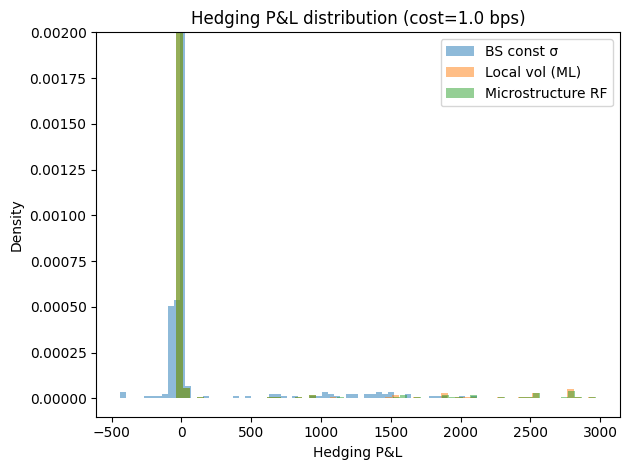

All experiments finished. Tables and figures are ready for the thesis.


In [ ]:
main()